## 📊 Cohort Retention Analysis (2009-2010 Dataset)

This notebook demonstrates a step-by-step Cohort Analysis for customer retention and revenue retention. Cohort analysis allows us to track user engagement and spending behavior over time based on their first purchase cohort.

### 1. Setup & Environment
We start by importing the necessary analytical and visualization libraries.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting style
sns.set_theme(style='whitegrid')
%matplotlib inline

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2. Loading the Dataset
We will load the raw sales transaction data from Google Drive and preview its structure.

In [9]:
# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Year 2009-2010.csv', encoding='latin-1')

# Standardize datetime parsing
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%Y %H:%M')

print("📊 Data Preview:")
display(df.head())

# Keep relevant analysis features (using .copy() to prevent SettingWithCopyWarning)
df = df[['Customer ID', 'InvoiceDate', 'Quantity', 'Price']].copy()

📊 Data Preview:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


### 3. Data Inspection & Cleaning
Before performing cohort segmentation, we must clean missing customer IDs, filter out negative returns/refunds, and ensure positive transaction pricing.

In [7]:
print("📈 Data Description:")
display(df.describe())

print("🔍 Missing Values Check:")
print(df.isnull().sum())
print(f"\n📏 Total Rows Before Cleaning: {len(df):,}")

# Drop rows where Customer ID is missing
df.dropna(subset=['Customer ID'], inplace=True)

# Remove returns (negative quantities) and invalid prices
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

# Calculate Total Transaction Value
df['Total_Amount'] = df['Quantity'] * df['Price']

print(f"✅ Rows Remaining After Cleaning: {len(df):,}")

📈 Data Description:


,Customer ID,InvoiceDate,Quantity,Price,Total_Amount,CohortIndex
count,407664.000000,407664,407664.000000,407664.000000,407664.000000,407664.000000
mean,15368.592598,2010-07-01 10:15:11.871688192,13.585585,3.294438,21.664909,4.016729
min,12346.000000,2009-12-01 07:45:00,1.000000,0.001000,0.001000,0.000000
25%,13997.000000,2010-03-26 14:01:00,2.000000,1.250000,4.950000,0.000000
50%,15321.000000,2010-07-09 15:47:00,5.000000,1.950000,11.900000,3.000000
75%,16812.000000,2010-10-14 17:09:00,12.000000,3.750000,19.500000,7.000000
max,18287.000000,2010-12-09 20:01:00,19152.000000,10953.500000,15818.400000,12.000000
std,1679.762138,NaN,96.840747,34.757965,77.150058,3.803355


🔍 Missing Values Check:
Customer ID     0
InvoiceDate     0
Quantity        0
Price           0
Total_Amount    0
OrderMonth      0
CohortMonth     0
CohortIndex     0
dtype: int64

📏 Total Rows Before Cleaning: 407,664
✅ Rows Remaining After Cleaning: 407,664


### 4. Cohort Feature Engineering
To assign each customer to an acquisition cohort, we extract the initial purchase month for each unique customer ID and calculate their activity indices.

In [5]:
# Step 1: Extract transaction order month
df['OrderMonth'] = df['InvoiceDate'].dt.to_period('M')

# Step 2: Establish the Cohort Month (Customer's First Purchase Month)
df['CohortMonth'] = df.groupby('Customer ID')['OrderMonth'].transform('min')

# Step 3: Compute the Cohort Index (Monthly delta since cohort initialization)
df['CohortIndex'] = (df['OrderMonth'] - df['CohortMonth']).apply(lambda x: x.n)

display(df.head())

,Customer ID,InvoiceDate,Quantity,Price,Total_Amount,OrderMonth,CohortMonth,CohortIndex
0,13085.0,2009-12-01 07:45:00,12,6.95,83.4,2009-12,2009-12,0
1,13085.0,2009-12-01 07:45:00,12,6.75,81.0,2009-12,2009-12,0
2,13085.0,2009-12-01 07:45:00,12,6.75,81.0,2009-12,2009-12,0
3,13085.0,2009-12-01 07:45:00,48,2.10,100.8,2009-12,2009-12,0
4,13085.0,2009-12-01 07:45:00,24,1.25,30.0,2009-12,2009-12,0


### 5. Customer Retention Cohort Analysis
Next, we construct the user-count matrix and calculate retention rates as percentages relative to the initial cohort size.

In [6]:
# Build pivot table representing active unique customers per cohort segment
Customer_CohortMatrix = df.pivot_table(
    index='CohortMonth',
    columns='CohortIndex',
    values='Customer ID',
    aggfunc='nunique'
)

# Calculate percentages relative to Month 0 (index 0)
Customer_CohortSize = Customer_CohortMatrix.iloc[:, 0]
Customer_RetentionMatrix = Customer_CohortMatrix.divide(Customer_CohortSize, axis=0) * 100

print("📊 Customer Retention Matrix (%):")
display(Customer_RetentionMatrix.round(1))

📊 Customer Retention Matrix (%):


CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2009-12,100.0,35.3,33.4,42.5,38.0,35.9,37.7,34.2,33.6,36.2,42.2,49.5,24.8
2010-01,100.0,20.6,31.1,30.5,26.4,30.0,25.8,23.0,27.9,31.9,30.3,9.9,NaN
2010-02,100.0,23.8,22.5,29.1,24.6,20.1,19.3,28.6,25.4,27.5,7.2,NaN,NaN
2010-03,100.0,19.0,23.0,24.2,23.3,20.3,24.6,30.2,27.5,7.9,NaN,NaN,NaN
2010-04,100.0,19.4,19.4,16.3,18.4,22.4,27.6,26.2,6.8,NaN,NaN,NaN,NaN
2010-05,100.0,15.7,16.9,17.3,17.7,25.6,21.3,7.9,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.4,18.9,20.4,23.0,28.5,6.7,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.6,18.3,29.6,29.0,10.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,20.4,29.6,32.1,11.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Customer Retention Heatmap Visualization

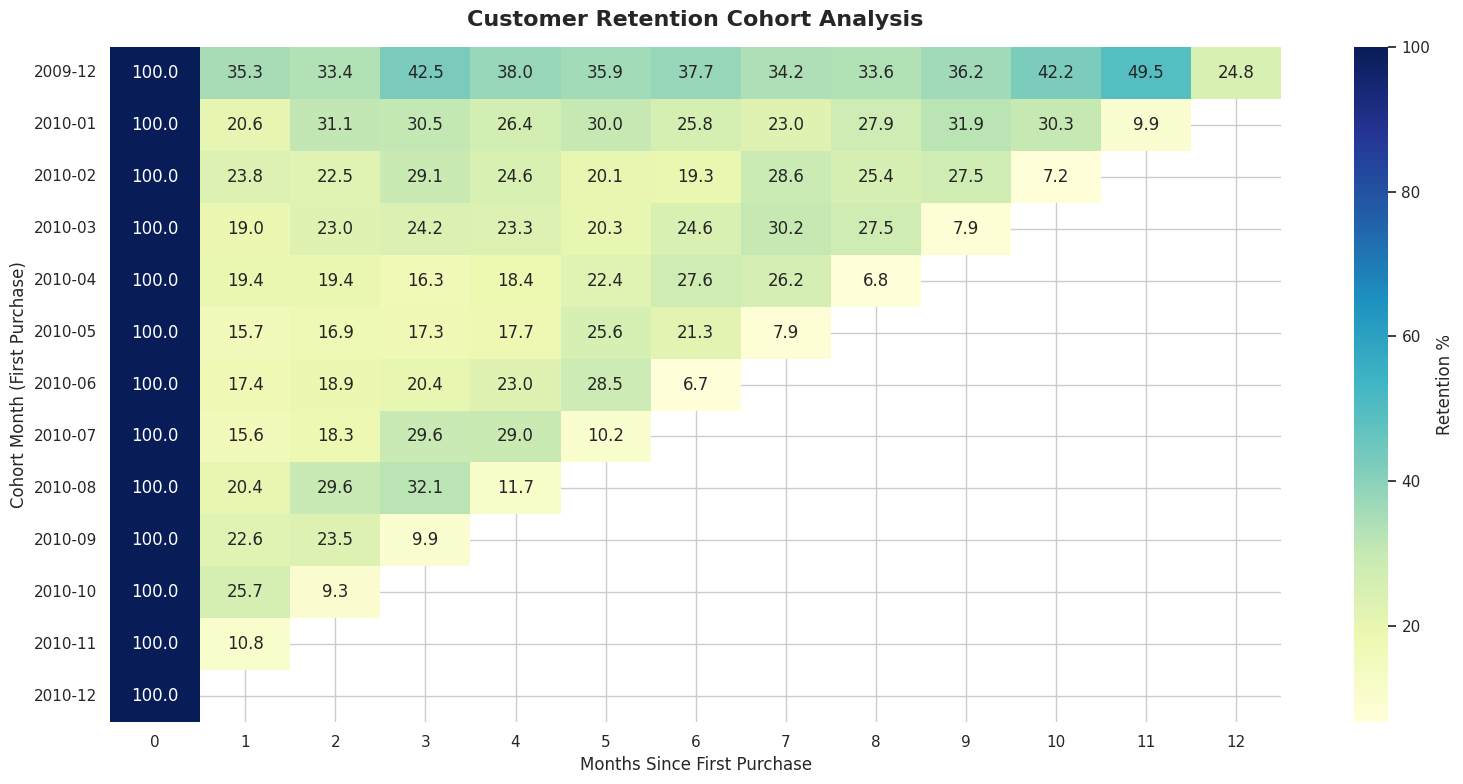

In [ ]:
plt.figure(figsize=(16, 8))
sns.heatmap(
    Customer_RetentionMatrix,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    cbar_kws={'label': 'Retention %'}
)
plt.title('Customer Retention Cohort Analysis', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('Cohort Month (First Purchase)', fontsize=12)
plt.xlabel('Months Since First Purchase', fontsize=12)
plt.tight_layout()
plt.show()

### 6. Revenue Retention Cohort Analysis
Similarly, we measure user monetary retention over time by analyzing total revenue patterns across successive cohorts.

In [ ]:
# Build pivot table representing total revenue generated per cohort segment
Revenue_CohortMatrix = df.pivot_table(
    index='CohortMonth',
    columns='CohortIndex',
    values='Total_Amount',
    aggfunc='sum'
)

# Calculate percentages relative to Month 0 (index 0)
Revenue_CohortSize = Revenue_CohortMatrix.iloc[:, 0]
Revenue_RetentionMatrix = Revenue_CohortMatrix.divide(Revenue_CohortSize, axis=0) * 100

print("📊 Revenue Retention Matrix (%):")
display(Revenue_RetentionMatrix.round(1))

📊 Revenue Retention Matrix (%):


CohortIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
CohortMonth,,,,,,,,,,,,,
2009-12,100.0,57.6,43.2,55.3,44.7,44.6,44.1,45.7,48.4,57.2,67.2,83.5,27.0
2010-01,100.0,24.2,31.6,35.7,36.4,37.8,32.2,29.8,37.4,46.2,47.6,13.6,NaN
2010-02,100.0,19.6,32.2,31.3,25.8,23.3,23.6,30.1,31.1,32.2,7.1,NaN,NaN
2010-03,100.0,21.2,22.1,27.5,21.4,23.8,27.9,34.7,32.6,6.0,NaN,NaN,NaN
2010-04,100.0,15.2,16.6,24.1,17.8,24.7,28.2,26.2,4.0,NaN,NaN,NaN,NaN
2010-05,100.0,12.3,12.8,11.6,15.2,28.3,21.1,4.2,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,12.2,17.1,19.6,26.6,36.8,7.1,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,11.1,18.3,33.2,38.4,9.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,22.6,37.9,38.5,13.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Revenue Retention Heatmap Visualization

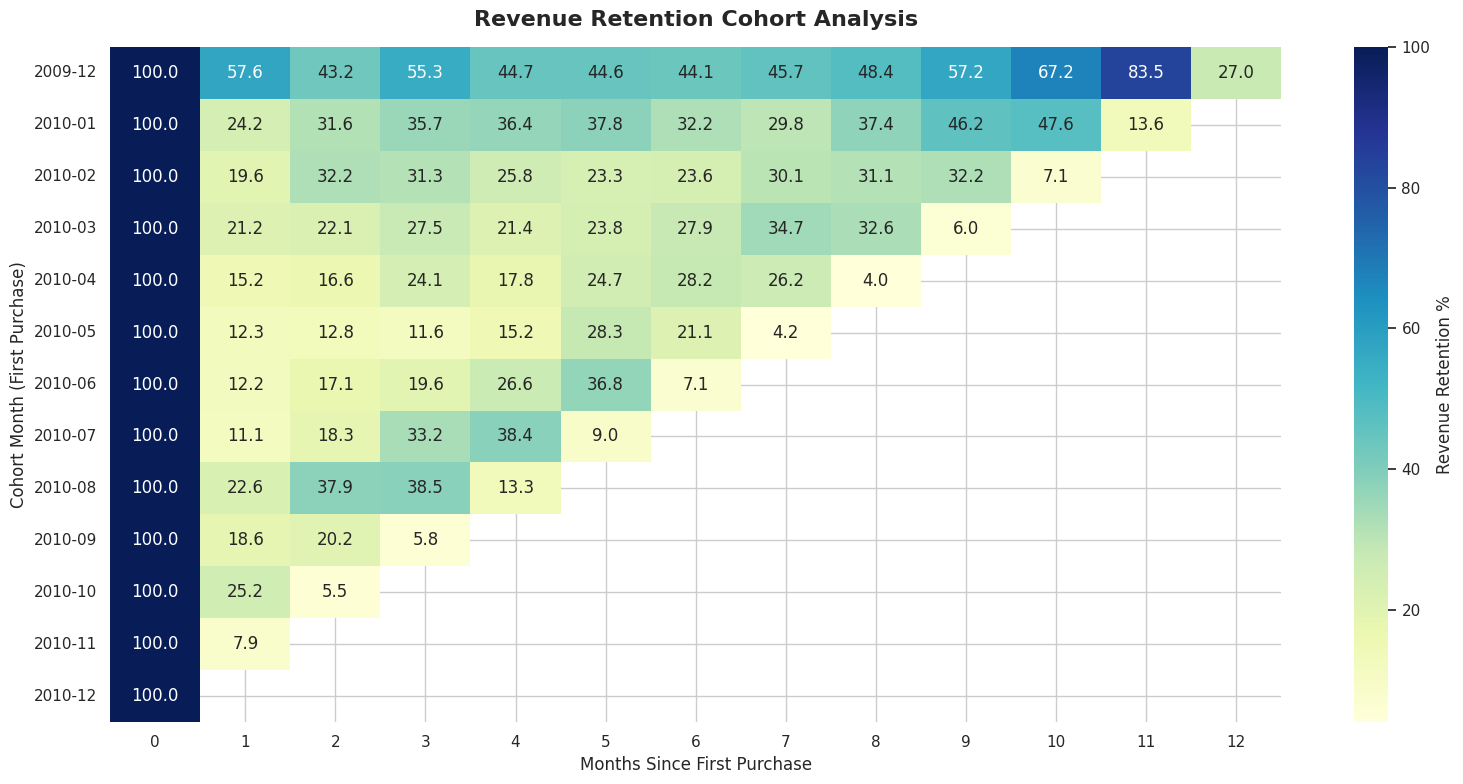

In [ ]:
plt.figure(figsize=(16, 8))
sns.heatmap(
    Revenue_RetentionMatrix,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    cbar_kws={'label': 'Revenue Retention %'}
)
plt.title('Revenue Retention Cohort Analysis', fontsize=16, fontweight='bold', pad=15)
plt.ylabel('Cohort Month (First Purchase)', fontsize=12)
plt.xlabel('Months Since First Purchase', fontsize=12)
plt.tight_layout()
plt.show()